# CA3

### Imports

Import all necessary packages.

In [305]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Reading data

Construct a relative file path, read a CSV file into a DataFrame, and print the first 5 rows.

In [306]:
current_folder = Path.cwd()
all_train_data_path = current_folder / "data" / "train.csv"
final_test_data_path = current_folder / "data" / "test.csv"

df = pd.read_csv(all_train_data_path, index_col="Id")

df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
Id,,,,,,,,,,,,
13,7.8,0.610,0.29,1.6,0.114,9.0,29.0,0.99740,3.26,1.56,9.1,0
705,8.4,1.035,0.15,6.0,0.073,11.0,54.0,0.99900,3.37,0.49,9.9,0
1408,8.1,0.290,0.36,2.2,0.048,35.0,53.0,0.99500,3.27,1.01,12.4,1
144,5.2,0.340,0.00,1.8,0.050,27.0,63.0,0.99160,3.68,0.79,14.0,1
557,15.6,0.645,0.49,4.2,0.095,10.0,23.0,1.00315,2.92,0.74,11.1,0


### Data exploration and cleaning

In [307]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000,835.000000
mean,8.310898,0.540042,0.260790,2.542994,0.088674,15.859880,47.077246,0.996799,3.308707,0.658048,10.396287,0.500599
std,1.757359,0.179786,0.197739,1.420451,0.051485,10.444733,33.271056,0.001946,0.159072,0.179891,1.087407,0.500299
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,7.000000,0.990070,2.740000,0.330000,8.400000,0.000000
25%,7.100000,0.410000,0.080000,1.900000,0.071000,7.000000,22.000000,0.995600,3.200000,0.550000,9.500000,0.000000
50%,7.900000,0.540000,0.240000,2.200000,0.080000,13.000000,38.000000,0.996750,3.310000,0.610000,10.100000,1.000000
75%,9.100000,0.647500,0.410000,2.600000,0.091000,21.000000,63.000000,0.997900,3.400000,0.725000,11.000000,1.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,1.000000


Check the data for missing values.

In [308]:
print("Missing values:", df.isna().sum().sum())

Missing values: 0


Check the data for duplicates (repeated rows), and remove them if they exist.

In [309]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after cleaning:", df.shape)

Duplicate rows: 75
Shape after cleaning: (760, 12)


Visualize the distributions of features using histograms and box plots.

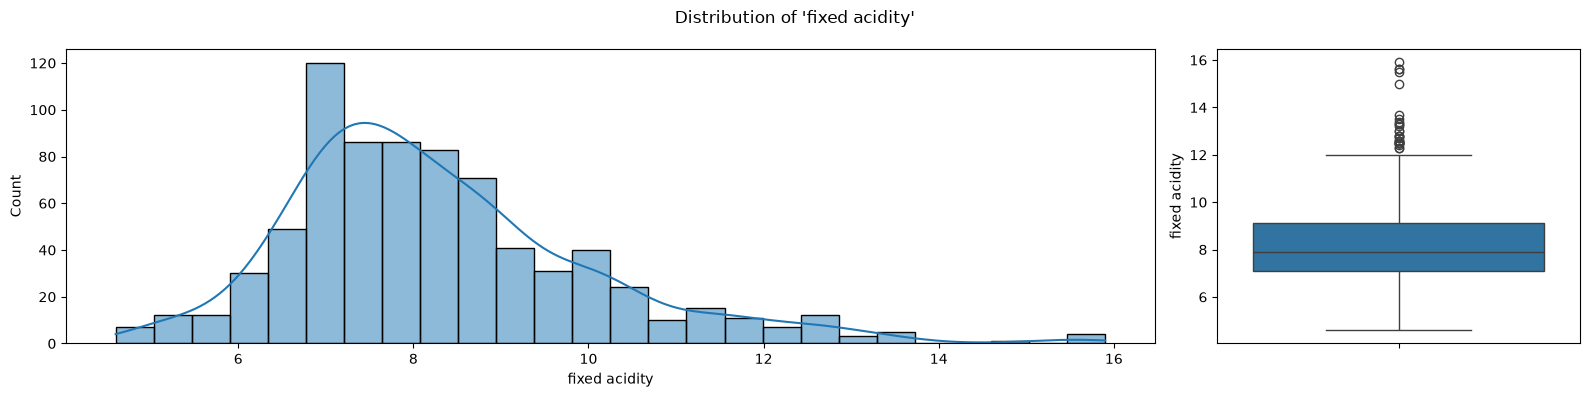

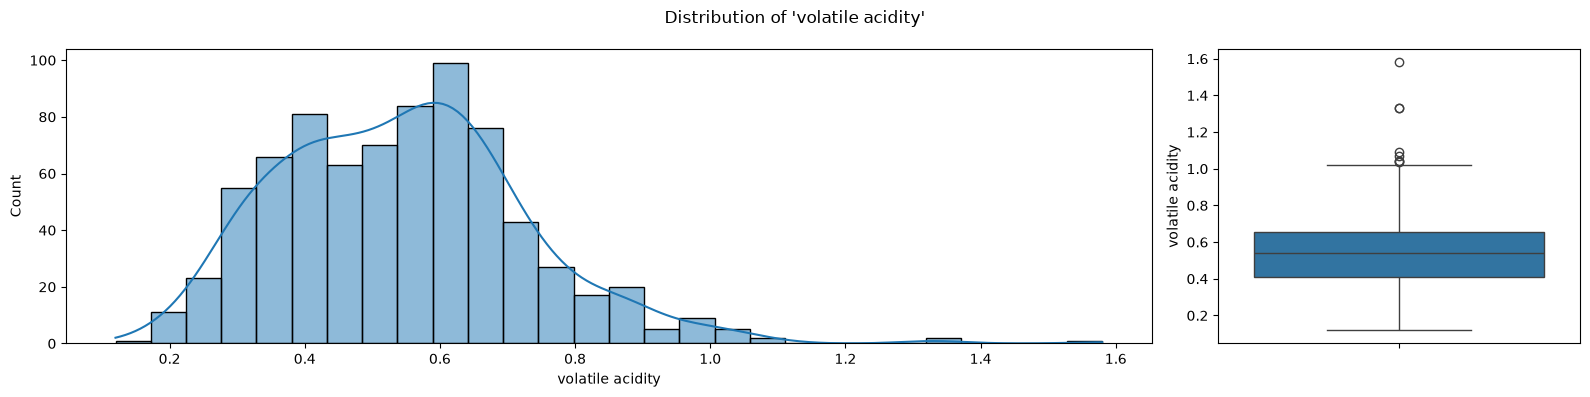

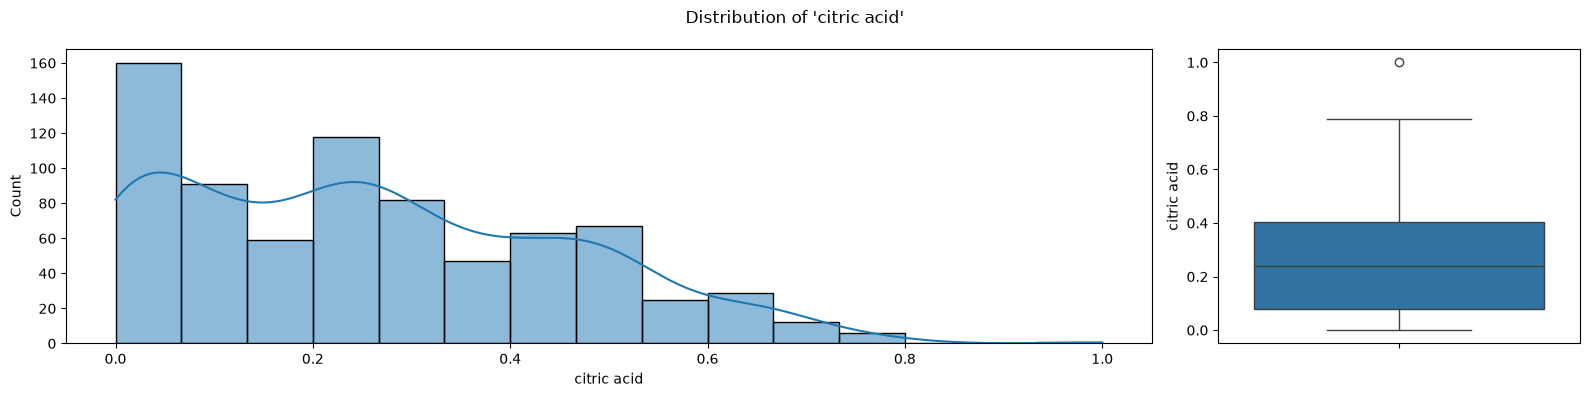

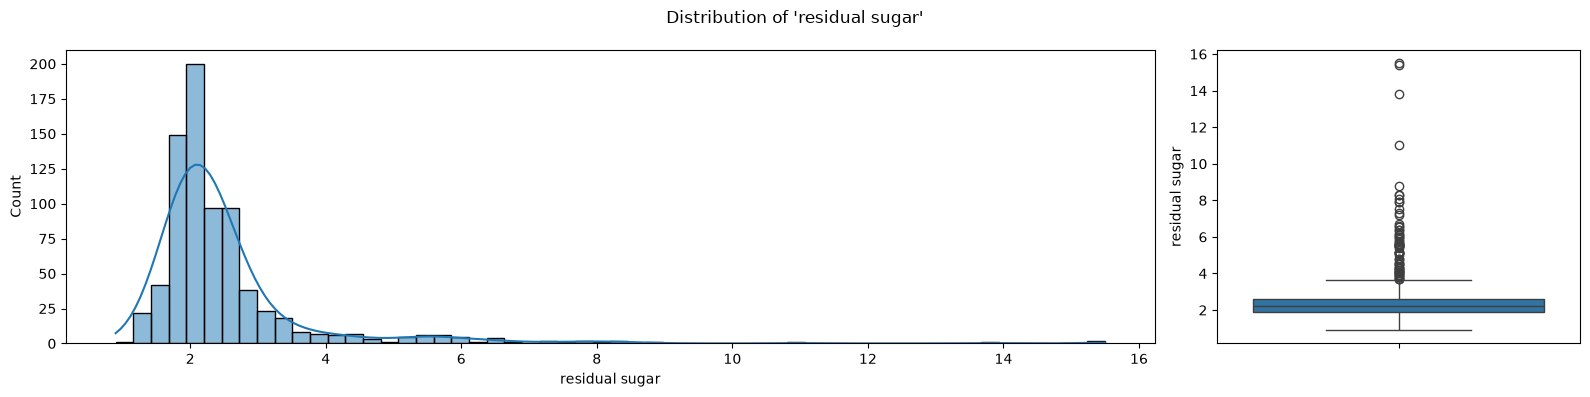

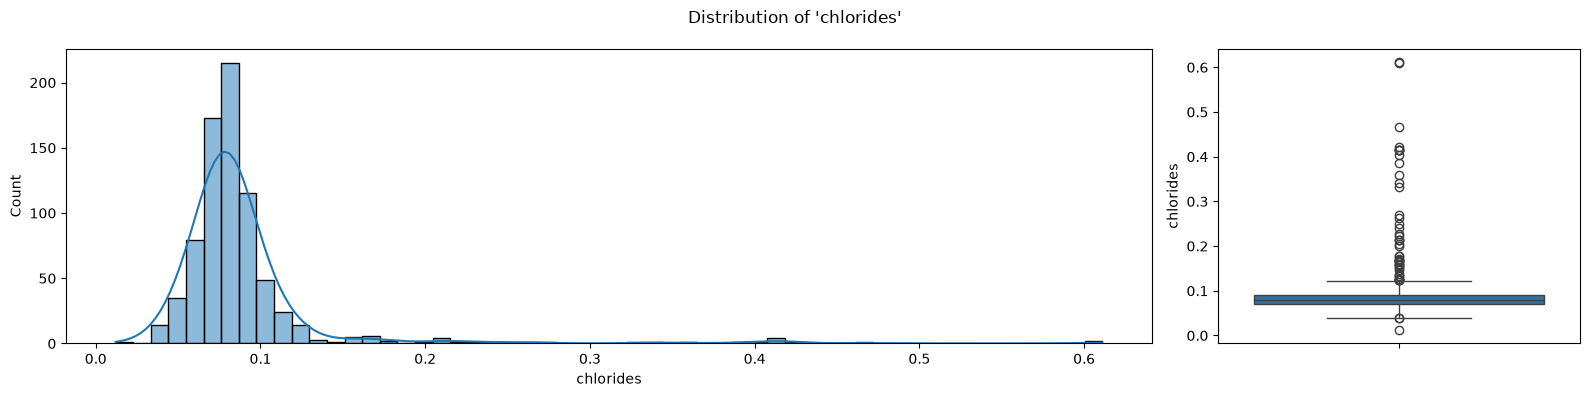

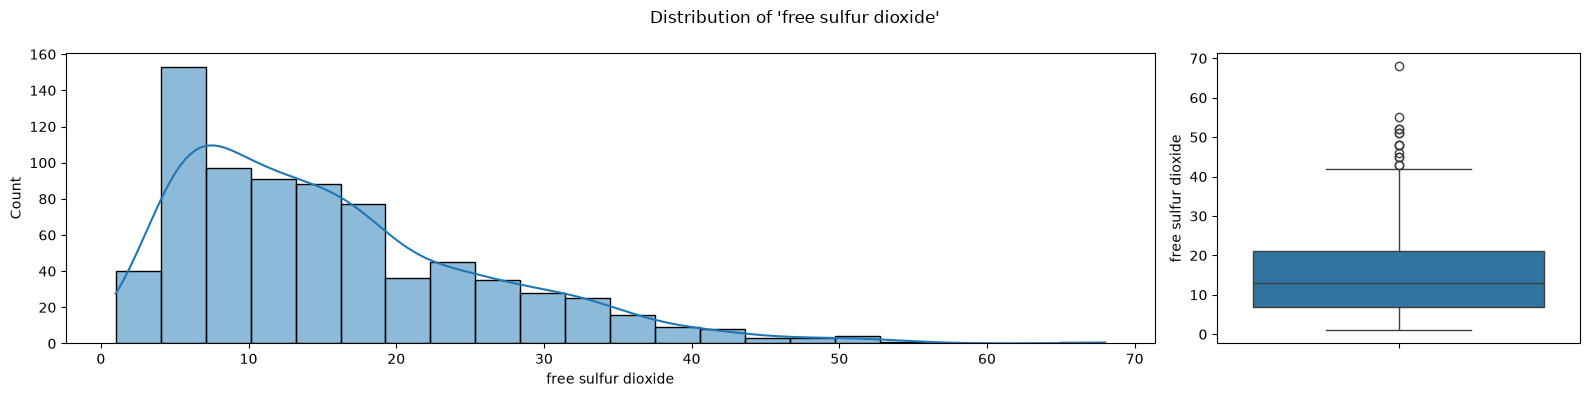

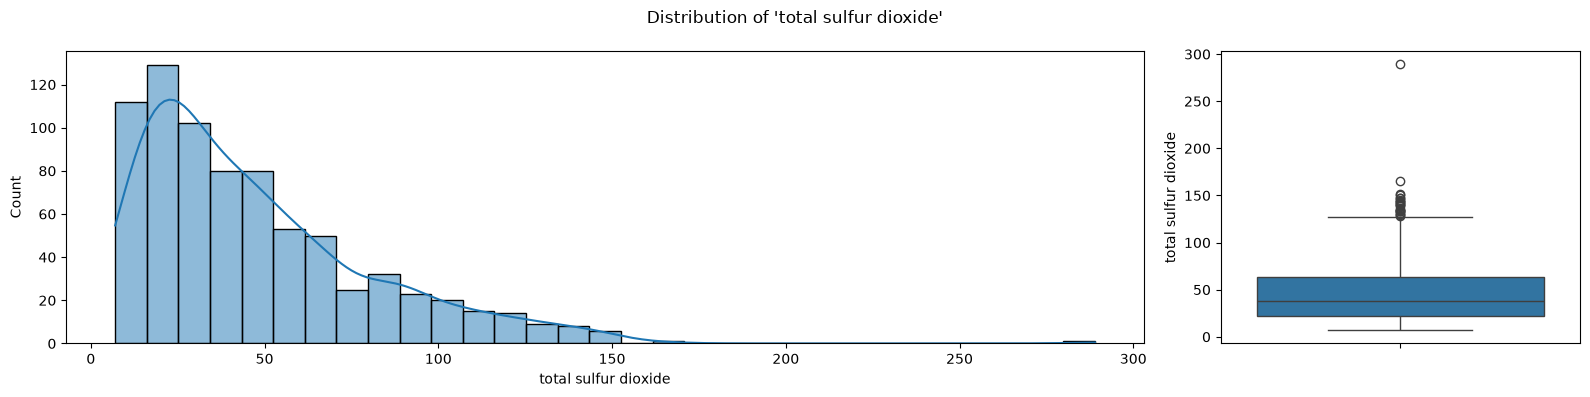

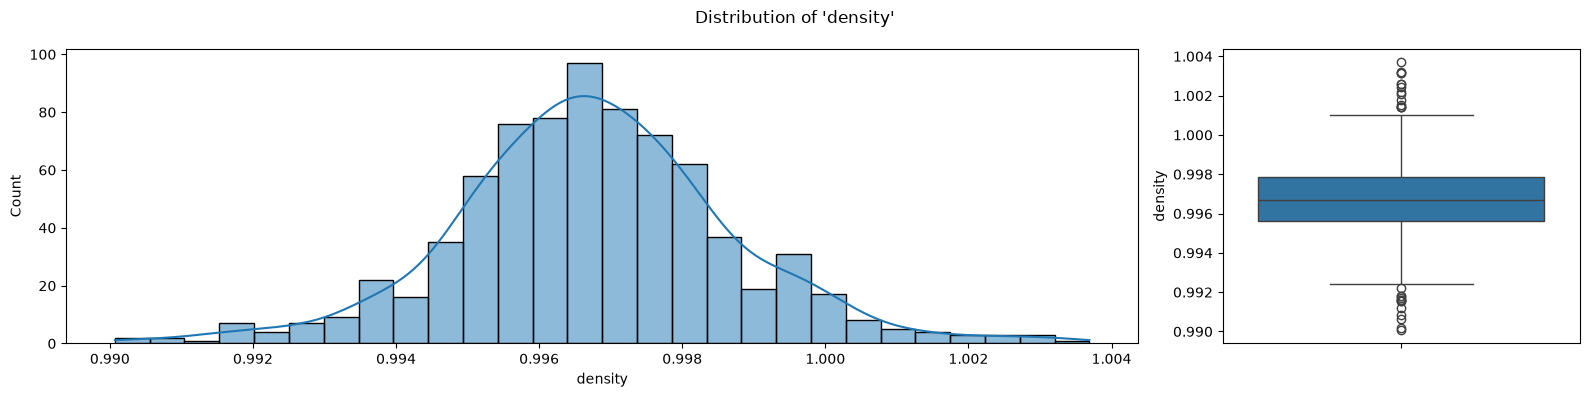

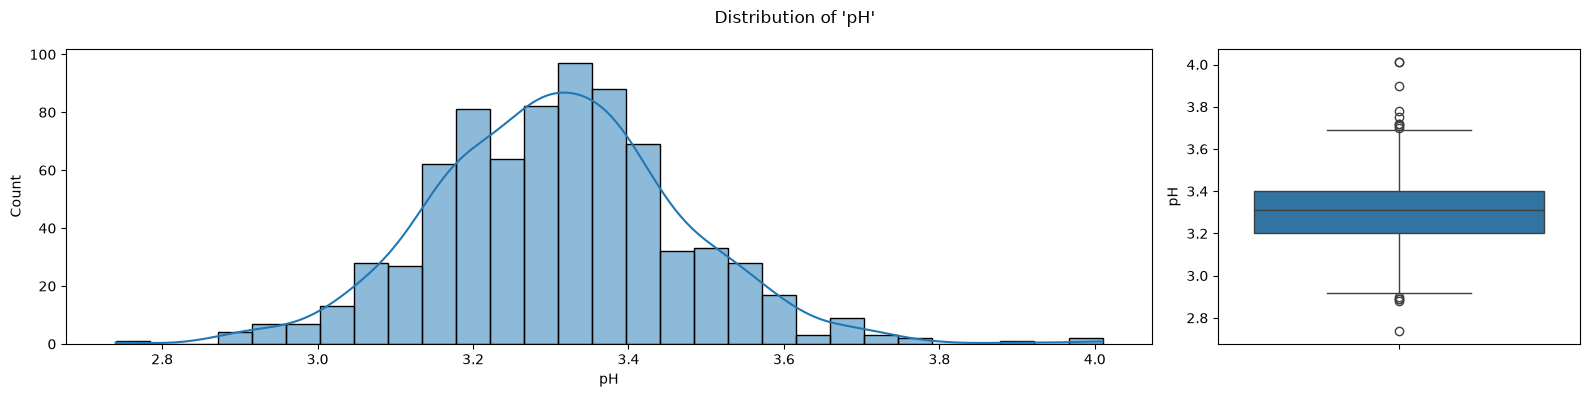

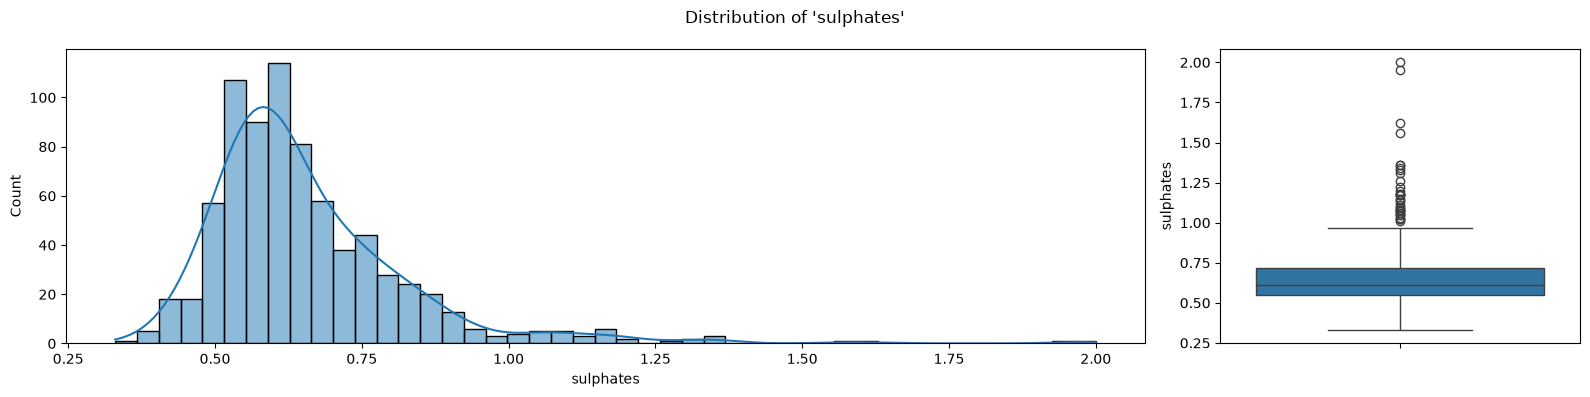

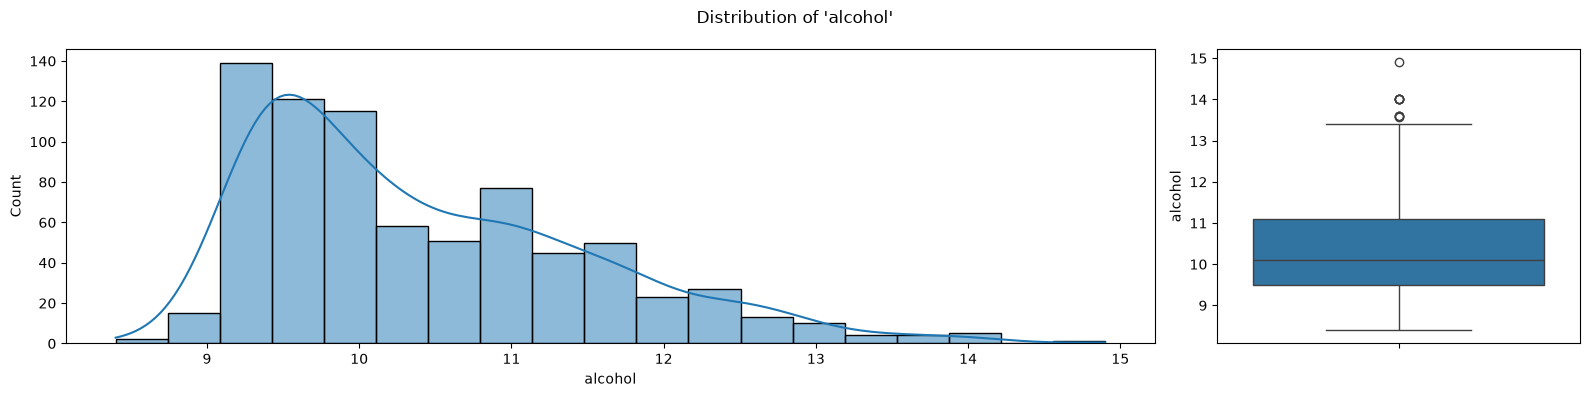

In [310]:
original_features = list(df.columns.drop("quality"))

for i, feature in enumerate(original_features):
    fig, axes = plt.subplots(
        1, 2, 
        figsize=(16, 4), 
        gridspec_kw={'width_ratios': [3, 1]} # histplots need more space than boxlots
        )

    sns.histplot(
        data=df[feature],
        ax=axes[0], 
        kde=True  # add a smooth line
    )

    sns.boxplot(data=df[feature], ax=axes[1])
    
    fig.suptitle(f"Distribution of '{feature}'")
    fig.tight_layout()


plt.show()

Many features appear to be skewed. Let's calculate their skewness.

In [311]:
original_features = list(df.columns.drop("quality"))

skewness = df[original_features].skew().sort_values(ascending=False)

print(f"{"Skewness of Features":^28}")
print(skewness.round(2).to_string())

    Skewness of Features    
chlorides               5.61
residual sugar          4.67
sulphates               2.50
total sulfur dioxide    1.48
free sulfur dioxide     1.16
fixed acidity           1.09
alcohol                 0.96
volatile acidity        0.70
citric acid             0.50
pH                      0.26
density                 0.08


### Data preprocessing

We can try to add some new features.

In [312]:
def add_features(data):
    data = data.copy()
    
    data["bound sulfur dioxide"] = data["total sulfur dioxide"] - data["free sulfur dioxide"]
    data["free/total sulfur dioxide"] = data["free sulfur dioxide"] / data["total sulfur dioxide"]
    data["molecular sulfur dioxide"] = data["free sulfur dioxide"] / (1 + 10 ** (data["pH"] - 1.81))

    data["total acidity"] = data["fixed acidity"] + data["volatile acidity"]
    data["fixed/volatile acidity"] = data["fixed acidity"] / data["volatile acidity"]

    data['wine_fraction_density'] = data['density'] - 0.789 * data['alcohol'] / 100
    
    return data

extended_df = add_features(df)



Save all skewed features.

In [313]:
skewed_features = extended_df.columns[extended_df.skew() > 1]
print(*skewed_features, sep='\n')

fixed acidity
residual sugar
chlorides
free sulfur dioxide
total sulfur dioxide
sulphates
bound sulfur dioxide
molecular sulfur dioxide
total acidity
fixed/volatile acidity


The `RBF` kernel measures distances between wine samples, so features should be on comparable scales. Otherwise, features such as `total sulfur dioxide` (with values up to 289) would dominate the distance calculations, while features such as `density` (with values close to 1) would contribute very little.

We will compare feature scaling approaches:
1) **Standard scaling**: Standardize all features to have a mean of 0 and a standard deviation of 1.
2) **Log transformation + standard scaling**: Apply a logarithmic transformation to skewed features, followed by standard scaling.
3) **Percentile rank transformation**: Convert feature values into percentile ranks by dividing their ranks by the total number of observations.

In [314]:
def standard_scaling(X_train, X_test=None):
    scaler = StandardScaler().fit(X_train)

    X_train = scaler.transform(X_train)

    if X_test is None:
        return X_train

    X_test = scaler.transform(X_test)
    
    return X_train, X_test


def log_scaling(X_train, X_test=None):
    skewed_train = list[set(skewed_features) & set(X_train.columns)]

    X_train = X_train.copy()
    X_train = X_train[skewed_train].apply(np.log1p)

    if X_test is None:
        return standard_scaling(X_train)
    
    X_test = X_test.copy()
    X_test[skewed_train] = X_test[skewed_train].apply(np.log1p)    

    return standard_scaling(X_train, X_test)


def percentile_scaling(X_train, X_test=None):
    n = len(X_train)

    sorted_train = {
        col: np.sort(X_train[col].to_numpy())
        for col in X_train.columns
    }

    X_train = pd.DataFrame({
        col: np.searchsorted(sorted_train[col], X_train[col], side="right") / n
        for col in X_train.columns
    }, index=X_train.index)

    if X_test is None:
        return X_train

    X_test = pd.DataFrame({
        col: np.searchsorted(sorted_train[col], X_test[col], side="right") / n
        for col in X_test.columns
    }, index=X_test.index)

    return X_train, X_test

### Modelling

Let's prepare splits for different random seeds in advance.

In [315]:
MAX_RS = 200

train_idx = []
test_idx = []

for rs in range(MAX_RS):
    train, test = train_test_split(range(len(df)), test_size = 0.2, random_state=rs, stratify=df["quality"])

    train_idx.append(train)
    test_idx.append(test)

Set ranges for C and gamma.

In [316]:
C_VALUES = [0.3, 1, 3, 4, 6, 8, 10, 20, 30]
GAMMA_VALUES = [0.003, 0.01, 0.02, 0.03, 0.04, 0.06, 0.1, 0.3]

param_grid = np.meshgrid(
    C_VALUES, 
    GAMMA_VALUES,
    indexing="ij"
)

combinations = np.array(
    [grid.ravel() for grid in param_grid],
    dtype=object
).T

Search for optimal combination.

In [317]:
X = df.drop(columns=["quality"])
y = df["quality"]

for scaling in [standard_scaling, log_scaling, percentile_scaling]:
    
    acc_test_range = np.zeros(len(combinations))

    for i, [C_val, gamma_val] in enumerate(combinations):

        accuracy_test = np.zeros(MAX_RS)

        for rs in range(MAX_RS):

            # Split into train and test
            X_train = X.iloc[train_idx[rs]]
            X_test = X.iloc[test_idx[rs]]
            
            y_train = y.iloc[train_idx[rs]]
            y_test = y.iloc[test_idx[rs]]

            X_train, X_test = scaling(X_train, X_test)

            # Train
            clf = svm.SVC(
                kernel="rbf",
                C=C_val,
                gamma=gamma_val,
                random_state=42
            ).fit(X_train, y_train)

            # Calculate accuracy
            accuracy_test[rs] = clf.score(X_test, y_test)

        acc_test_range[i] = accuracy_test.mean()

    best_i = acc_test_range.argmax()
    print(
        f"{scaling.__name__} | C = {combinations[best_i][0]} |"
        f" gamma = {combinations[best_i][1]} | accuracy = {acc_test_range[best_i]:.5f}"
    )

standard_scaling | C = 1.0 | gamma = 0.1 | accuracy = 0.73938
log_scaling | C = 3.0 | gamma = 0.1 | accuracy = 0.74263
percentile_scaling | C = 8.0 | gamma = 0.3 | accuracy = 0.75266


Choose the best combination.

In [318]:
best_scaling = percentile_scaling

best_params = {
    "kernel": "rbf",
    "C": 8.0,
    "gamma": 0.3,
}

best_accuracy = 0.75266

Try to add new features.

In [ ]:
new_features = [
    "bound sulfur dioxide", "free/total sulfur dioxide",
    "molecular sulfur dioxide", "total acidity",
    "fixed/volatile acidity", "wine_fraction_density"
]

for feature in new_features:
    experimental_features = original_features + [feature]

    X = extended_df[experimental_features]

    accuracy_test = np.zeros(MAX_RS)

    for rs in range(MAX_RS):

        # Split into train and test
        X_train = X.iloc[train_idx[rs]]
        X_test = X.iloc[test_idx[rs]]
        
        y_train = y.iloc[train_idx[rs]]
        y_test = y.iloc[test_idx[rs]]

        X_train, X_test = best_scaling(X_train, X_test)

        # Train
        clf = svm.SVC(
            **best_params,
            random_state=42
        ).fit(X_train, y_train)

        # Calculate accuracy
        accuracy_test[rs] = clf.score(X_test, y_test)

    new_accuracy = accuracy_test.mean()

    print(f" + {feature:<26}: {(new_accuracy - best_accuracy):>8.5f}")

    

 + bound sulfur dioxide      : -0.00194
 + free/total sulfur dioxide : -0.00457
 + molecular sulfur dioxide  : -0.00388
 + total acidity             : -0.00039
 + fixed/volatile acidity    : -0.00046
 + wine_fraction_density     : -0.00210


Try to remove the features.

In [320]:
for i, feature in enumerate(original_features):
    experimental_features = original_features[:i] + original_features[i + 1:]

    X = extended_df[experimental_features]

    accuracy_test = np.zeros(MAX_RS)

    for rs in range(MAX_RS):

        # Split into train and test
        X_train = X.iloc[train_idx[rs]]
        X_test = X.iloc[test_idx[rs]]
        
        y_train = y.iloc[train_idx[rs]]
        y_test = y.iloc[test_idx[rs]]

        X_train, X_test = best_scaling(X_train, X_test)

        # Train
        clf = svm.SVC(
            **best_params,
            random_state=42
        ).fit(X_train, y_train)

        # Calculate accuracy
        accuracy_test[rs] = clf.score(X_test, y_test)

    new_accuracy = accuracy_test.mean()

    print(f" - {feature:<26}: {(new_accuracy - best_accuracy):>8.5f}")

 - fixed acidity             : -0.00154
 - volatile acidity          : -0.01190
 - citric acid               : -0.00993
 - residual sugar            : -0.00302
 - chlorides                 :  0.00408
 - free sulfur dioxide       : -0.00286
 - total sulfur dioxide      : -0.00562
 - density                   : -0.00210
 - pH                        : -0.00069
 - sulphates                 : -0.01592
 - alcohol                   : -0.01411


It make sense to remove `chlorides`.

In [321]:
final_features = original_features.copy()
final_features.remove("chlorides")

### Final evaluation

In [328]:
X_train = df[final_features]
y_train = y

X_test = pd.read_csv(final_test_data_path, index_col="Id")[final_features]

X_train, X_test = best_scaling(X_train, X_test)

clf = svm.SVC(
    **best_params,
    random_state=42
).fit(X_train, y_train)

### Kaggle submission

In [329]:
y_test = clf.predict(X_test)
y_test = pd.DataFrame(y_test, columns=["quality"])
y_test.index.name = "Id"

predictions_path = current_folder / "data" / "SVM.csv"

y_test.to_csv(predictions_path, index=True)